In [5]:
library(lme4)
library(lmerTest)
library(emmeans)
library(dplyr)

In [6]:
df <- read.csv("concatenated_data/f0_z_onset_offset_processed.csv")

df$tone <- as.factor(df$tone)
df$lang <- as.factor(df$lang)
df$onset_segment_type <- as.factor(df$onset_segment)
df$offset_segment_type <- as.factor(df$offset_segment)
df$position <- as.factor(df$position)
df$participant <- as.factor(df$participant)
df <- df[!df$participant %in% c("P9", "P11"),]

# role-based portion indices, from the RAW values (0 = portion closest to the boundary)
df$target_portion_idx  <- ifelse(df$position == "carryover",
                                 df$onset_portion_idx, df$offset_portion_idx)
df$context_portion_idx <- ifelse(df$position == "carryover",
                                 df$offset_portion_idx, df$onset_portion_idx)

# scale once
df$target_portion_idx  <- as.vector(scale(df$target_portion_idx))
df$context_portion_idx <- as.vector(scale(df$context_portion_idx))

## Overall

In [7]:
contrasts(df$tone) <- contr.sum(length(unique(df$tone)))
print(contrasts(df$tone))

contrasts(df$lang) <- contr.sum(length(unique(df$lang)))
print(contrasts(df$lang))

# contrasr code as -0.5 and 0.5
contrasts(df$position) <- c(-0.5, 0.5)
print(contrasts(df$position))

   [,1] [,2] [,3] [,4]
21    1    0    0    0
33    0    1    0    0
35    0    0    1    0
51    0    0    0    1
55   -1   -1   -1   -1
              [,1] [,2]
man              1    0
man_bilingual    0    1
min             -1   -1
             [,1]
anticipatory -0.5
carryover     0.5


In [8]:
temp <- df

model <- lmer(y ~ x*lang*tone*position*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 40 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 200 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
y ~ x * lang * tone * position * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 26768

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-6.3175 -0.4336 -0.0075  0.4353  6.6859 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 1.337e-02 0.115632      
                     x           1.339e-02 0.115697 -0.37
 offset_segment_type (Intercept) 6.580e-03 0.081115      
                     x           7.635e-03 0.087378 -0.70
 onset_segment_type  (Intercept) 1.940e-03 0.044045      
                     x           1.491e-05 0.003861 -1.00
 Residual                        5.893e-01 0.767632      
Number of obs: 11160, groups:  
participant, 23; offset_segment_type, 4; onset_segment_type, 2

Fixed effect

### Residual analysis

Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
`geom_smooth()` using formula = 'y ~ x'


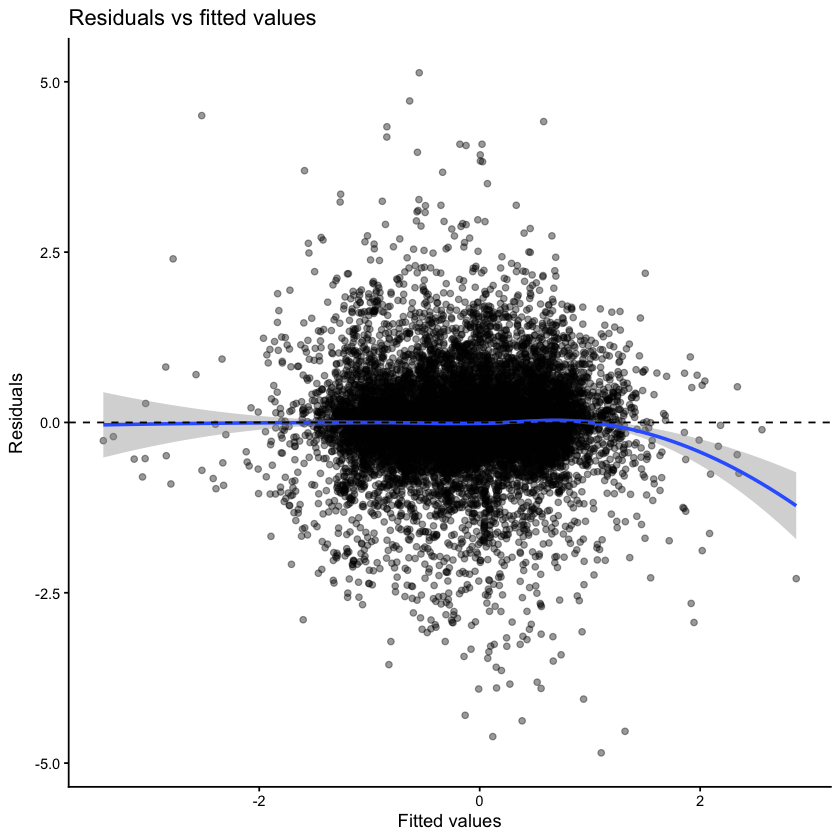

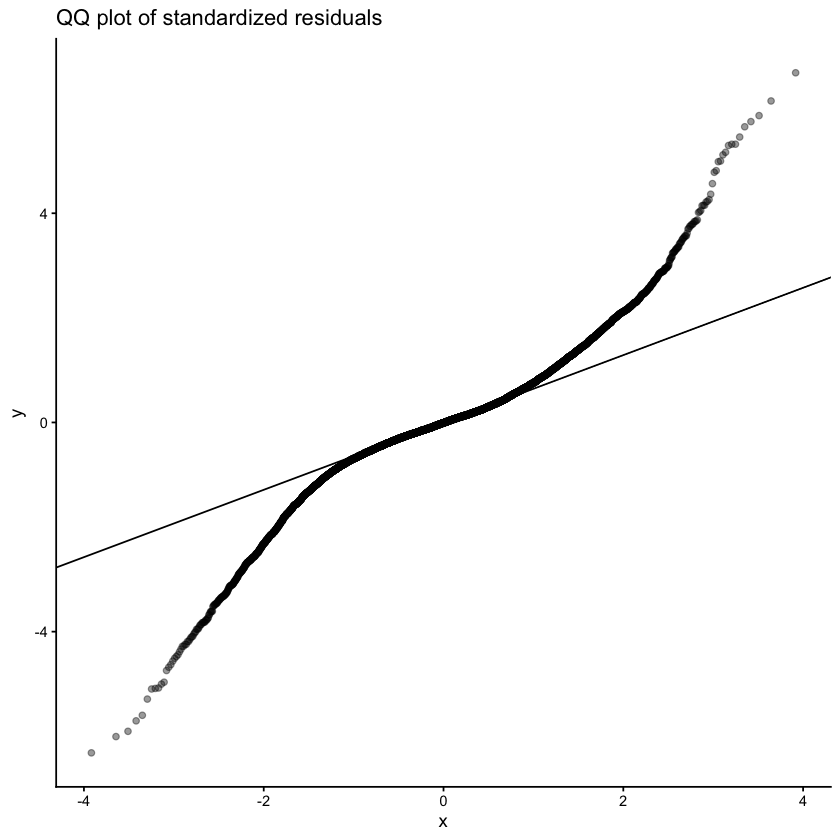

`geom_smooth()` using formula = 'y ~ x'


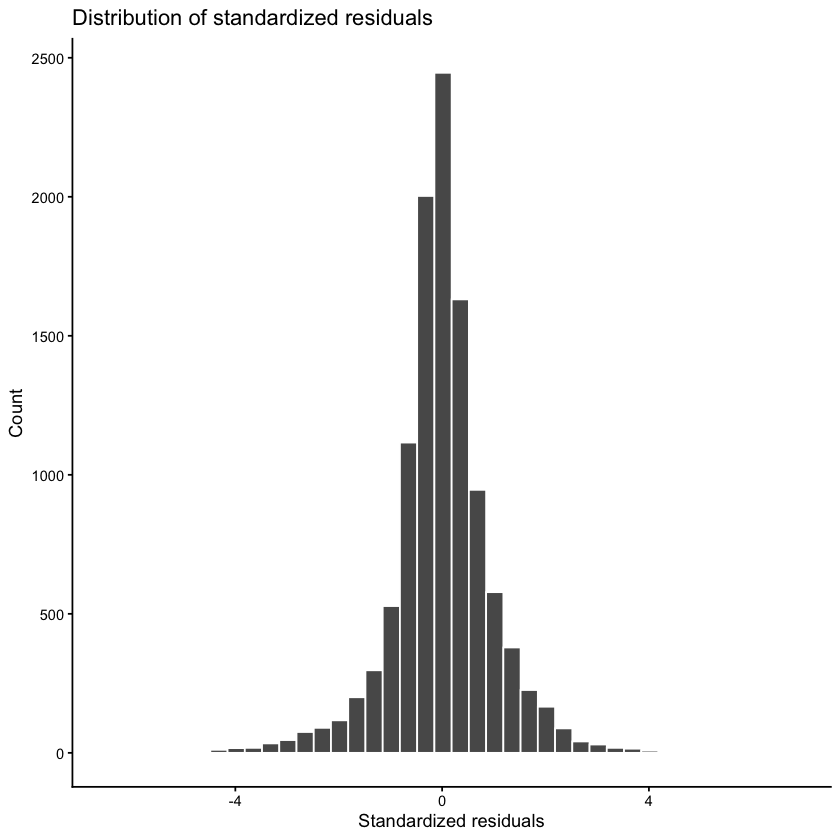

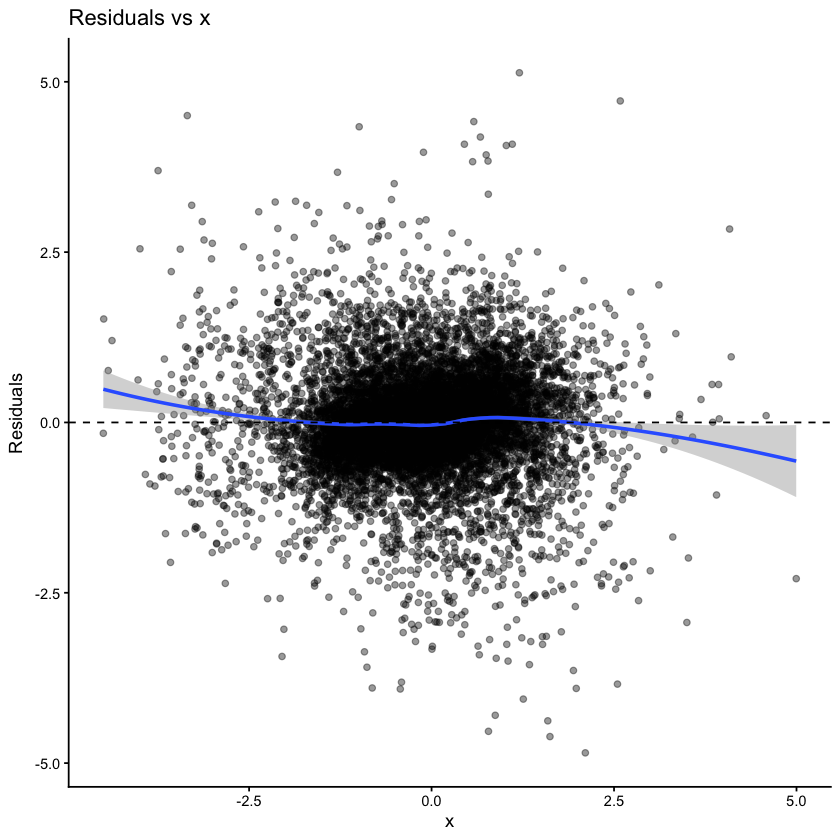

In [9]:
library(ggplot2)
diag_df <- model.frame(model) %>%
  mutate(
    fitted = fitted(model),
    resid = resid(model),
    pearson_resid = residuals(model, type = "pearson"),
    std_resid = resid / sigma(model),

    
    abs_std_resid = abs(std_resid)
  )

ggplot(diag_df, aes(x = fitted, y = resid)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "loess", se = TRUE) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  theme_classic() +
  labs(
    x = "Fitted values",
    y = "Residuals",
    title = "Residuals vs fitted values"
  )

ggplot(diag_df, aes(sample = std_resid)) +
  stat_qq(alpha = 0.4) +
  stat_qq_line() +
  theme_classic() +
  labs(title = "QQ plot of standardized residuals")

ggplot(diag_df, aes(x = std_resid)) +
  geom_histogram(bins = 40, color = "white") +
  theme_classic() +
  labs(
    x = "Standardized residuals",
    y = "Count",
    title = "Distribution of standardized residuals"
  )

ggplot(diag_df, aes(x = x, y = resid)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "loess", se = TRUE) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  theme_classic() +
  labs(
    x = "x",
    y = "Residuals",
    title = "Residuals vs x"
  )

### Excluding outliers

In [10]:
library(dplyr)

df$model_resid <- resid(model)
# Standardize the residuals and filter out extremes (keeping those within 2.5 SDs)
df_clean <- df %>%
  filter(abs(scale(model_resid)) < 2.5)

print(nrow(df) - nrow(df_clean))
# percentage
print((nrow(df) - nrow(df_clean)) / nrow(df) * 100)

Warning message:
“Using one column matrices in `filter()` was deprecated in dplyr 1.1.0.
ℹ Please use one dimensional logical vectors instead.”


[1] 364
[1] 3.261649


In [11]:
model <- lmer(y ~ x*lang*tone*position*target_portion_idx*context_portion_idx + 
                      (x | onset_segment_type) + 
                      (x | offset_segment_type) + 
                      (x | participant), 
                    data = df_clean)

summary(model)

fixed-effect model matrix is rank deficient so dropping 40 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 200 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
y ~ x * lang * tone * position * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: df_clean

REML criterion at convergence: 20652

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9650 -0.4975 -0.0197  0.4816  3.5055 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 1.070e-02 0.103436      
                     x           1.359e-02 0.116596 -0.01
 offset_segment_type (Intercept) 5.994e-03 0.077423      
                     x           8.795e-03 0.093784 -0.49
 onset_segment_type  (Intercept) 1.394e-03 0.037334      
                     x           9.823e-05 0.009911 -1.00
 Residual                        3.579e-01 0.598255      
Number of obs: 10796, groups:  
participant, 23; offset_segment_type, 4; onset_segment_type, 2

Fixed ef

In [12]:
# Look at the random slopes for onset segment type
ranef(model)$onset_segment_type

# Look at the random slopes for offset segment type
ranef(model)$offset_segment_type

,(Intercept),x
,<dbl>,<dbl>
N,-0.02493605,0.00661973
V,0.02493605,-0.00661973


,(Intercept),x
,<dbl>,<dbl>
L,-0.09629969,0.03850225
N,-0.01404155,-0.02137114
S,0.02541909,0.09989649
V,0.08492215,-0.11702760


In [13]:
trends <- emtrends(
  model,
  ~ lang,
  var = "x",
  weights = "flat"
)

summary(trends, infer = c(TRUE, TRUE))
pairs(trends)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 10796' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 10796)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 10796' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 10796)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,lang,x.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,man,0.3097637,0.06006409,Inf,0.1920403,0.4274872,5.157220,2.506430e-07
2,man_bilingual,0.2741215,0.06107595,Inf,0.1544148,0.3938282,4.488207,7.182526e-06
3,min,0.4484924,0.06123005,Inf,0.3284837,0.5685010,7.324710,2.394150e-13


 contrast            estimate     SE  df z.ratio p.value
 man - man_bilingual   0.0356 0.0529 Inf   0.674  0.7786
 man - min            -0.1387 0.0534 Inf  -2.598  0.0254
 man_bilingual - min  -0.1744 0.0223 Inf  -7.812  <.0001

Results are averaged over the levels of: tone, position 
Degrees-of-freedom method: asymptotic 
P value adjustment: tukey method for comparing a family of 3 estimates 

### The effects when only the most distal portions are considered

In [14]:
trends <- emtrends(
  model,
  ~ lang,
  var = "x",
  weights = "flat",
  at = list(target_portion_idx = c(max(df_clean$target_portion_idx)),
            context_portion_idx = c(max(df_clean$context_portion_idx)))
)

summary(trends, infer = c(TRUE, TRUE))
pairs(trends)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 10796' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 10796)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 10796' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 10796)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,lang,x.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,man,0.32240273,0.08724884,Inf,0.1513981380,0.4934073,3.695209,0.0002197058
2,man_bilingual,-0.01578336,0.10828989,Inf,-0.2280276385,0.1964609,-0.145751,0.8841179796
3,min,0.24197366,0.12386196,Inf,-0.0007913212,0.4847386,1.953575,0.0507514700


 contrast            estimate    SE  df z.ratio p.value
 man - man_bilingual   0.3382 0.121 Inf   2.788  0.0147
 man - min             0.0804 0.136 Inf   0.592  0.8245
 man_bilingual - min  -0.2578 0.141 Inf  -1.822  0.1622

Results are averaged over the levels of: tone, position 
Degrees-of-freedom method: asymptotic 
P value adjustment: tukey method for comparing a family of 3 estimates 

## Within-language comparisons

### Taiwan Mandarin (monolingual)

In [15]:
temp <- df_clean

temp <- temp[temp$lang == "man",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*position*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 64 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6465.1

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.2844 -0.5440 -0.0158  0.5138  3.3009 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 1.827e-02 1.352e-01      
                     x           1.967e-02 1.402e-01 -0.03
 offset_segment_type (Intercept) 1.561e-02 1.250e-01      
                     x           5.486e-03 7.407e-02 0.12 
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           2.029e-11 4.505e-06  NaN 
 Residual                        4.224e-01 6.499e-01      
Number of obs: 3081, groups:  
participant, 12; offset_segment_type, 4; onset_segment_type, 2

Fixed effect

In [16]:
temp <- df_clean

temp <- temp[temp$lang == "man",]
temp <- temp[temp$position == "carryover",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3138.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5480 -0.4973 -0.0154  0.5085  3.2159 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 2.494e-02 1.579e-01      
                     x           2.753e-02 1.659e-01 0.28 
 offset_segment_type (Intercept) 3.355e-02 1.832e-01      
                     x           5.751e-03 7.584e-02 -0.05
 onset_segment_type  (Intercept) 5.161e-11 7.184e-06      
                     x           2.830e-12 1.682e-06 -1.00
 Residual                        3.928e-01 6.267e-01      
Number of obs: 1535, groups:  
participant, 12; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

In [17]:
temp <- df_clean

temp <- temp[temp$lang == "man",]
temp <- temp[temp$position == "anticipatory",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3274.3

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4269 -0.5780 -0.0611  0.5112  3.0418 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 3.355e-02 1.832e-01      
                     x           1.199e-02 1.095e-01 -0.25
 offset_segment_type (Intercept) 7.392e-04 2.719e-02      
                     x           1.184e-02 1.088e-01 1.00 
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           1.077e-11 3.282e-06  NaN 
 Residual                        4.271e-01 6.536e-01      
Number of obs: 1546, groups:  
participant, 12; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

### Taiwan Southern Min

In [18]:
temp <- df_clean

temp <- temp[temp$lang == "min",]

model <- lmer(y ~ x*position*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 8 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 72 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6449.6

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.9926 -0.4840 -0.0191  0.4283  4.6781 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0040084 0.06331       
                     x           0.0078739 0.08874  0.05 
 offset_segment_type (Intercept) 0.0068815 0.08295       
                     x           0.0132321 0.11503  -0.61
 onset_segment_type  (Intercept) 0.0010580 0.03253       
                     x           0.0001909 0.01382  -1.00
 Residual                        0.2046216 0.45235       
Number of obs: 4830, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
     

### Taiwan Mandarin (bilingual)

In [19]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*position*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 64 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6672.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.2447 -0.5985 -0.0100  0.6085  2.7101 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr
 participant         (Intercept) 9.093e-03 0.095357     
                     x           9.351e-03 0.096701 0.22
 offset_segment_type (Intercept) 1.728e-02 0.131450     
                     x           2.041e-02 0.142871 0.16
 onset_segment_type  (Intercept) 5.717e-03 0.075610     
                     x           1.888e-06 0.001374 1.00
 Residual                        5.286e-01 0.727048     
Number of obs: 2885, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
             

## Within-position comparisons

In [20]:
temp <- df_clean
temp <- temp[temp$position == "carryover",]

model <- lmer(y ~ x*lang*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 16 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 104 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * lang * tone * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 10103.4

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.0134 -0.4807 -0.0282  0.4863  3.4613 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0172191 0.13122       
                     x           0.0201321 0.14189  0.29 
 offset_segment_type (Intercept) 0.0137264 0.11716       
                     x           0.0074356 0.08623  0.19 
 onset_segment_type  (Intercept) 0.0002864 0.01692       
                     x           0.0002168 0.01473  -1.00
 Residual                        0.3419145 0.58473       
Number of obs: 5372, groups:  
participant, 23; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
        

In [21]:
temp <- df_clean
temp <- temp[temp$position == "anticipatory",]

model <- lmer(y ~ x*lang*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 24 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 96 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * lang * tone * target_portion_idx * context_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 10316.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5847 -0.5374 -0.0146  0.4655  3.5912 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.020723 0.14395       
                     x           0.010908 0.10444  -0.07
 offset_segment_type (Intercept) 0.009998 0.09999       
                     x           0.014902 0.12207  -0.70
 onset_segment_type  (Intercept) 0.005640 0.07510       
                     x           0.001419 0.03767  -1.00
 Residual                        0.351756 0.59309       
Number of obs: 5424, groups:  
participant, 23; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                

## Pairwise tone comparisons

### TSM carryover

In [22]:
temp <- df_clean

temp <- temp[temp$lang == "min",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))

if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3] [,4]
21    1    0    0    0
33    0    1    0    0
35    0    0    1    0
51    0    0    0    1
55   -1   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 40 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 2813

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-5.8033 -0.4832 -0.0408  0.4316  5.3139 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr
 participant         (Intercept) 7.690e-03 0.087691     
                     x           1.313e-02 0.114584 0.37
 offset_segment_type (Intercept) 5.651e-03 0.075172     
                     x           3.881e-02 0.196997 0.66
 onset_segment_type  (Intercept) 2.204e-04 0.014845     
                     x           1.774e-05 0.004211 1.00
 Residual                        1.689e-01 0.411009     
Number of obs: 2405, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                                

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.750 0.116 4.23    0.435    1.066
 33     0.628 0.115 4.97    0.331    0.924
 35     0.579 0.117 4.04    0.255    0.904
 51     0.651 0.119 4.47    0.333    0.968
 55     0.462 0.112 4.28    0.160    0.765

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone33   0.1226 0.0654  694.5   1.875  0.3318
 tone21 - tone35   0.1708 0.0362 2209.8   4.715  <.0001
 tone21 - tone51   0.0997 0.0591 1484.3   1.687  0.4421
 tone21 - tone55   0.2878 0.0598   38.8   4.815  0.0002
 tone33 - tone35   0.0482 0.0665  326.8   0.726  0.9504
 tone33 - tone51  -0.0229 0.0601  220.0  -0.381  0.9955
 tone33 - tone55   0.1652 0.0645  945.4   2.562  0.0785
 tone35 - tone51  -0.0711 0.0561 1465.0  -1.268  0.7107
 tone35 - tone55   0.1169 0.0620   16.5   1.887  0.3616
 tone51 - tone55   0.1881 0.0771   48.2   2.439  0.1224

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 5 estimates 

### TM (monolingual) carryover

In [23]:
temp <- df_clean

temp <- temp[temp$lang == "man",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3138.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5480 -0.4973 -0.0154  0.5085  3.2159 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 2.494e-02 1.579e-01      
                     x           2.753e-02 1.659e-01 0.28 
 offset_segment_type (Intercept) 3.355e-02 1.832e-01      
                     x           5.751e-03 7.584e-02 -0.05
 onset_segment_type  (Intercept) 5.161e-11 7.184e-06      
                     x           2.830e-12 1.682e-06 -1.00
 Residual                        3.928e-01 6.267e-01      
Number of obs: 1535, groups:  
participant, 12; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE    df lower.CL upper.CL
 21     0.177 0.1260  4.07  -0.1707    0.525
 35     0.122 0.0913  6.73  -0.0957    0.340
 51     0.427 0.0811  8.18   0.2407    0.613
 55     0.249 0.0799 13.99   0.0771    0.420

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone35   0.0552 0.0779  94.63   0.709  0.8933
 tone21 - tone51  -0.2499 0.0822  14.26  -3.041  0.0385
 tone21 - tone55  -0.0714 0.1130   7.56  -0.630  0.9193
 tone35 - tone51  -0.3051 0.0636 152.18  -4.801  <.0001
 tone35 - tone55  -0.1267 0.0816  67.30  -1.553  0.4125
 tone51 - tone55   0.1785 0.0663 419.10   2.692  0.0370

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (bilingual) carryover

In [24]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')

Warning message:
“Model failed to converge with 1 negative eigenvalue: -3.2e-01”

Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3363

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.12106 -0.55628 -0.00943  0.60529  2.55987 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0239078 0.15462       
                     x           0.0157089 0.12534  -0.17
 offset_segment_type (Intercept) 0.0581438 0.24113       
                     x           0.0004472 0.02115  1.00 
 onset_segment_type  (Intercept) 0.0000000 0.00000       
                     x           0.0180893 0.13450   NaN 
 Residual                        0.5421142 0.73628       
Number of obs: 1432, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.184 0.135 1.83   -0.450    0.818
 35     0.191 0.128 1.96   -0.371    0.752
 51     0.284 0.119 1.51   -0.427    0.995
 55     0.276 0.118 1.64   -0.354    0.905

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone35 -0.00701 0.0919  32.5  -0.076  0.9998
 tone21 - tone51 -0.10018 0.0816 246.2  -1.228  0.6099
 tone21 - tone55 -0.09193 0.1070  43.9  -0.861  0.8246
 tone35 - tone51 -0.09317 0.0885  84.0  -1.053  0.7190
 tone35 - tone55 -0.08492 0.1040 112.2  -0.818  0.8460
 tone51 - tone55  0.00825 0.0872 171.1   0.095  0.9997

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TSM anticipatory

In [25]:
temp <- df_clean

temp <- temp[temp$lang == "min",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
33    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3285.2

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.2940 -0.4943  0.0107  0.4748  4.2614 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.013619 0.11670       
                     x           0.010219 0.10109  -0.24
 offset_segment_type (Intercept) 0.040208 0.20052       
                     x           0.005526 0.07434  -1.00
 onset_segment_type  (Intercept) 0.004176 0.06462       
                     x           0.003956 0.06290  -1.00
 Residual                        0.206314 0.45422       
Number of obs: 2425, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                              

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE   df lower.CL upper.CL
 21     0.504 0.0756 3.98    0.294    0.714
 33     0.632 0.0800 4.35    0.417    0.847
 51     0.649 0.0774 4.57    0.444    0.853
 55     0.477 0.0809 4.02    0.253    0.701

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone33  -0.1283 0.0467 299.6  -2.749  0.0320
 tone21 - tone51  -0.1447 0.0460 833.6  -3.144  0.0093
 tone21 - tone55   0.0271 0.0443 219.7   0.612  0.9282
 tone33 - tone51  -0.0165 0.0534 313.0  -0.308  0.9898
 tone33 - tone55   0.1553 0.0425 575.2   3.656  0.0016
 tone51 - tone55   0.1718 0.0550  78.5   3.124  0.0131

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (monolingual) anticipatory

In [26]:
temp <- df_clean

temp <- temp[temp$lang == "man",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3274.3

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4269 -0.5780 -0.0611  0.5112  3.0418 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 3.355e-02 1.832e-01      
                     x           1.199e-02 1.095e-01 -0.25
 offset_segment_type (Intercept) 7.392e-04 2.719e-02      
                     x           1.184e-02 1.088e-01 1.00 
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           1.077e-11 3.282e-06  NaN 
 Residual                        4.271e-01 6.536e-01      
Number of obs: 1546, groups:  
participant, 12; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE    df lower.CL upper.CL
 21   0.31381 0.1060 18.54   0.0924    0.535
 35   0.00145 0.0866  5.63  -0.2138    0.217
 51   0.18394 0.1010  6.26  -0.0605    0.428
 55   0.29187 0.0751  5.85   0.1070    0.477

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone35   0.3124 0.0891  507.5   3.506  0.0028
 tone21 - tone51   0.1299 0.1040  190.4   1.252  0.5943
 tone21 - tone55   0.0219 0.0829 1221.8   0.264  0.9935
 tone35 - tone51  -0.1825 0.0652  472.4  -2.800  0.0272
 tone35 - tone55  -0.2904 0.0570   82.0  -5.094  <.0001
 tone51 - tone55  -0.1079 0.0822   45.5  -1.313  0.5595

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (bilingual) anticipatory

In [27]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*target_portion_idx*context_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * target_portion_idx * context_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3216.2

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.05900 -0.63566 -0.02809  0.55249  3.03277 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.017344 0.13170       
                     x           0.013200 0.11489  0.61 
 offset_segment_type (Intercept) 0.001750 0.04184       
                     x           0.036567 0.19123  -1.00
 onset_segment_type  (Intercept) 0.046515 0.21567       
                     x           0.009086 0.09532  -1.00
 Residual                        0.471040 0.68632       
Number of obs: 1453, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                    

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.501 0.144 5.88   0.1461    0.856
 35     0.265 0.143 4.30  -0.1218    0.652
 51     0.494 0.151 4.21   0.0815    0.906
 55     0.143 0.130 4.26  -0.2082    0.494

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone35  0.23590 0.0877 200.5   2.690  0.0385
 tone21 - tone51  0.00695 0.0980  69.5   0.071  0.9999
 tone21 - tone55  0.35810 0.0769 977.8   4.659  <.0001
 tone35 - tone51 -0.22895 0.0597 575.4  -3.838  0.0008
 tone35 - tone55  0.12220 0.0684  74.4   1.785  0.2884
 tone51 - tone55  0.35115 0.0846  23.2   4.149  0.0020

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 